In [124]:
import numpy as np
import matplotlib.pyplot as plt
from slmcontrol import *
from PIL import Image

In [55]:
slm = SLMDisplay(monitor_id=1)
print(slm.width, slm.height)

x = np.arange(slm.width) - slm.width / 2
y = np.arange(slm.height) - slm.height / 2
x, y = np.meshgrid(x, y, sparse=True)


1920 1080


In [125]:
braia = Image.open('braia.png').convert('L').resize((slm.width, slm.height))


In [129]:
alfa = 0*np.exp(1j*np.pi*0)

input = lg(x,y, 0,0, w=500)
desired = (x**2 + y**2)*(hg(x,y, 1,1, w=100) + alfa*hg(x,y, 0,0, w=100))
#(1*x + np.max(x))*
desired = np.sqrt(braia)
relative = desired/input
holo = generate_hologram(relative, 255, 3, 4)
slm.updateArray(holo)

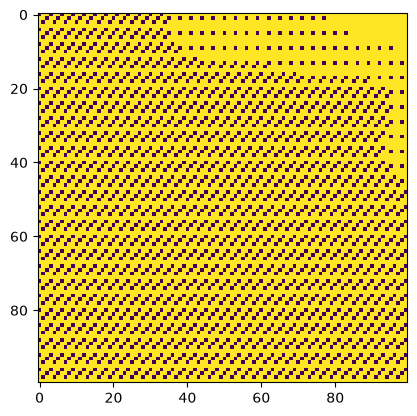

In [130]:
plt.imshow(holo[slm.height//2 -50: slm.height//2 + 50, slm.width//2 - 50: slm.width//2 + 50])

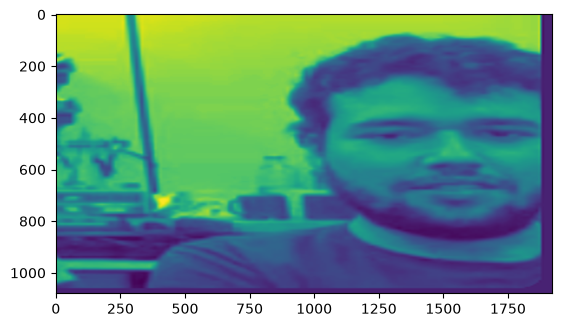

In [131]:
plt.imshow(np.abs(desired)**2)

In [132]:
slm.close()